# 16 장비 전용 모델 후속 연구: 03M02

약20분의 파일럿 범위에서 최대3대까지 선정하기로 했으며, 사전 최소 조건을 모두 통과한03M02 한 대를 CUDA 학습했습니다. 전용 학습 효과와 장비별 임계값만 조정한 효과를 분리해 비교합니다.

**후반20%는 이전 평가에서 이미 본 데이터이므로 독립 Holdout 시험이 아닙니다.** 기존 공통 모델과 최종 평가 파일을 보존했습니다. 이 Notebook은 저장된 후반 점수만 읽으며 전용 모델의 재현 확인에는 validation128행만 사용합니다.

In [1]:
from pathlib import Path
import sys,json,hashlib
import numpy as np,pandas as pd
from IPython.display import display,Image
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.specialist_experiment import OUT,PROTOCOL,readjson,digest,verify_previous,load
from src.common import TABLES,CFG
assert Path(sys.executable).resolve()==Path(CFG['python']).resolve()
def table(name):return pd.read_parquet(TABLES/('stage7_'+name+'.parquet'))
def figure(name):display(Image(filename=str(ROOT/('outputs/figures/stage7/'+name+'.png'))))
verify_previous()
selection=readjson(OUT/'selection.json')
frozen=readjson(OUT/'frozen_manifest.json')
access=readjson(OUT/'evaluation_access.json')
assert access['status']=='complete' and not access['independent_final_test']
assert access['specialist_prediction_passes_per_tool']==1
print('선정 장비:',selection['selected_tools'],'| 환경:',sys.executable)
display(PROTOCOL)

선정 장비: ['03M02'] | 환경: C:\Users\fl27\anaconda3\envs\phm2018\python.exe


{'experiment': '장비별 전용 모델 후속 연구',
 'maximum_tools': 3,
 'family': 'B',
 'cohort': 'maximum',
 'H': 600,
 'L': 60,
 'seed': 42,
 'eligibility': {'train_positive_clusters': 8,
  'validation_positive_clusters': 3,
  'train_positive_rows': 100,
  'validation_positive_rows': 20,
  'train_negative_rows': 1000,
  'validation_negative_rows': 1000},
 'cluster_rule': '양성 입력이 존재하는 비태그 고장을 시각순 정렬하여 인접 고장 간격이600 raw 초과일 때 새 군집. 독립 고장 표본임을 보장하지 않음',
 'ranking': '자격 충족 장비 중 train_positive_clusters 내림차순, train_positive_rows 내림차순, Tool 오름차순으로 최대3대. 후반 구간 결과는 선정에 사용하지 않음',
 'training': '기존 시간 train60%의 해당 장비 알려진 라벨만 fit. validation20%로 조기 종료. B 특징, 깊이3, 양성가중1, eta0.05, 최대1000, earlystop50, seed42. CUDA 순차, CPU12',
 'budgets': [5, 10],
 'comparators': ['global_frozen', 'global_tool_threshold', 'specialist'],
 'threshold_rule': 'global_frozen은 stage6 숫자 임계값 그대로. 나머지는 장비 validation의 고정12개+점수분위수16개 후보에서 상한 내 검출 최대, 부담 최소, 높은 임계값 순. 후반 예측 전에 숫자 동결',
 'evaluation': '기존 마지막20%를 후속 연구 비교에 사용. 이전 연구에서 이미 확인한 구간이

## 1. 선정과 제외

학습/검증 고장군집8/3개, 양성100/20행, 음성1,000/1,000행의 최소 조건입니다. 군집 간격은600 raw이며 독립 사건임을 보장하지 않습니다. 선정은 학습·검증 구간만 사용했습니다. 08M01은 검증 음성984개로 사전 기준에16개 못 미쳐 제외했습니다. 경계가 물리적인 충분성 기준이라는 뜻은 아니지만 결과에 맞춰 변경하지 않았습니다. 음성0은 정상 운전 부재가 아니라 현재 보수적 라벨 근거 부족을 뜻합니다.

,Tool,train_recorded_events,train_available_events,train_positive_events,train_positive_clusters,train_positive_rows,train_negative_rows,train_all_input_rows,validation_recorded_events,validation_available_events,validation_positive_events,validation_positive_clusters,validation_positive_rows,validation_negative_rows,validation_all_input_rows,eligible,reason,selected
0,01M01,12,6,6,6,37,49023,98447,3,0,0,0,0,0,28349,False,train_positive_clusters=6 < 8; validation_posi...,False
1,01M02,81,41,41,37,338,169404,178892,8,7,7,6,58,0,64845,False,validation_negative_rows=0 < 1000,False
2,02M01,5,4,4,4,20,0,92866,9,3,3,3,21,9805,25241,False,train_positive_clusters=4 < 8; train_positive_...,False
3,02M02,23,6,6,6,35,0,110194,5,1,1,1,9,0,35341,False,train_positive_clusters=6 < 8; validation_posi...,False
4,03M01,76,14,14,14,90,0,97148,9,3,3,3,28,0,25366,False,train_positive_rows=90 < 100; train_negative_r...,False
5,03M02,238,83,83,83,500,123296,134198,91,23,23,23,133,5982,41467,True,조건 충족,True
6,04M01,6,6,6,5,38,2490,134367,3,0,0,0,0,0,41601,False,train_positive_clusters=5 < 8; validation_posi...,False
7,04M02,2,2,2,2,18,0,163360,16,10,10,10,87,0,57175,False,train_positive_clusters=2 < 8; train_positive_...,False
8,05M01,22,10,10,10,52,10555,118175,1,1,1,1,2,0,42060,False,validation_positive_clusters=1 < 3; train_posi...,False
9,05M02,18,2,2,2,12,28051,50375,1,0,0,0,0,0,12904,False,train_positive_clusters=2 < 8; validation_posi...,False


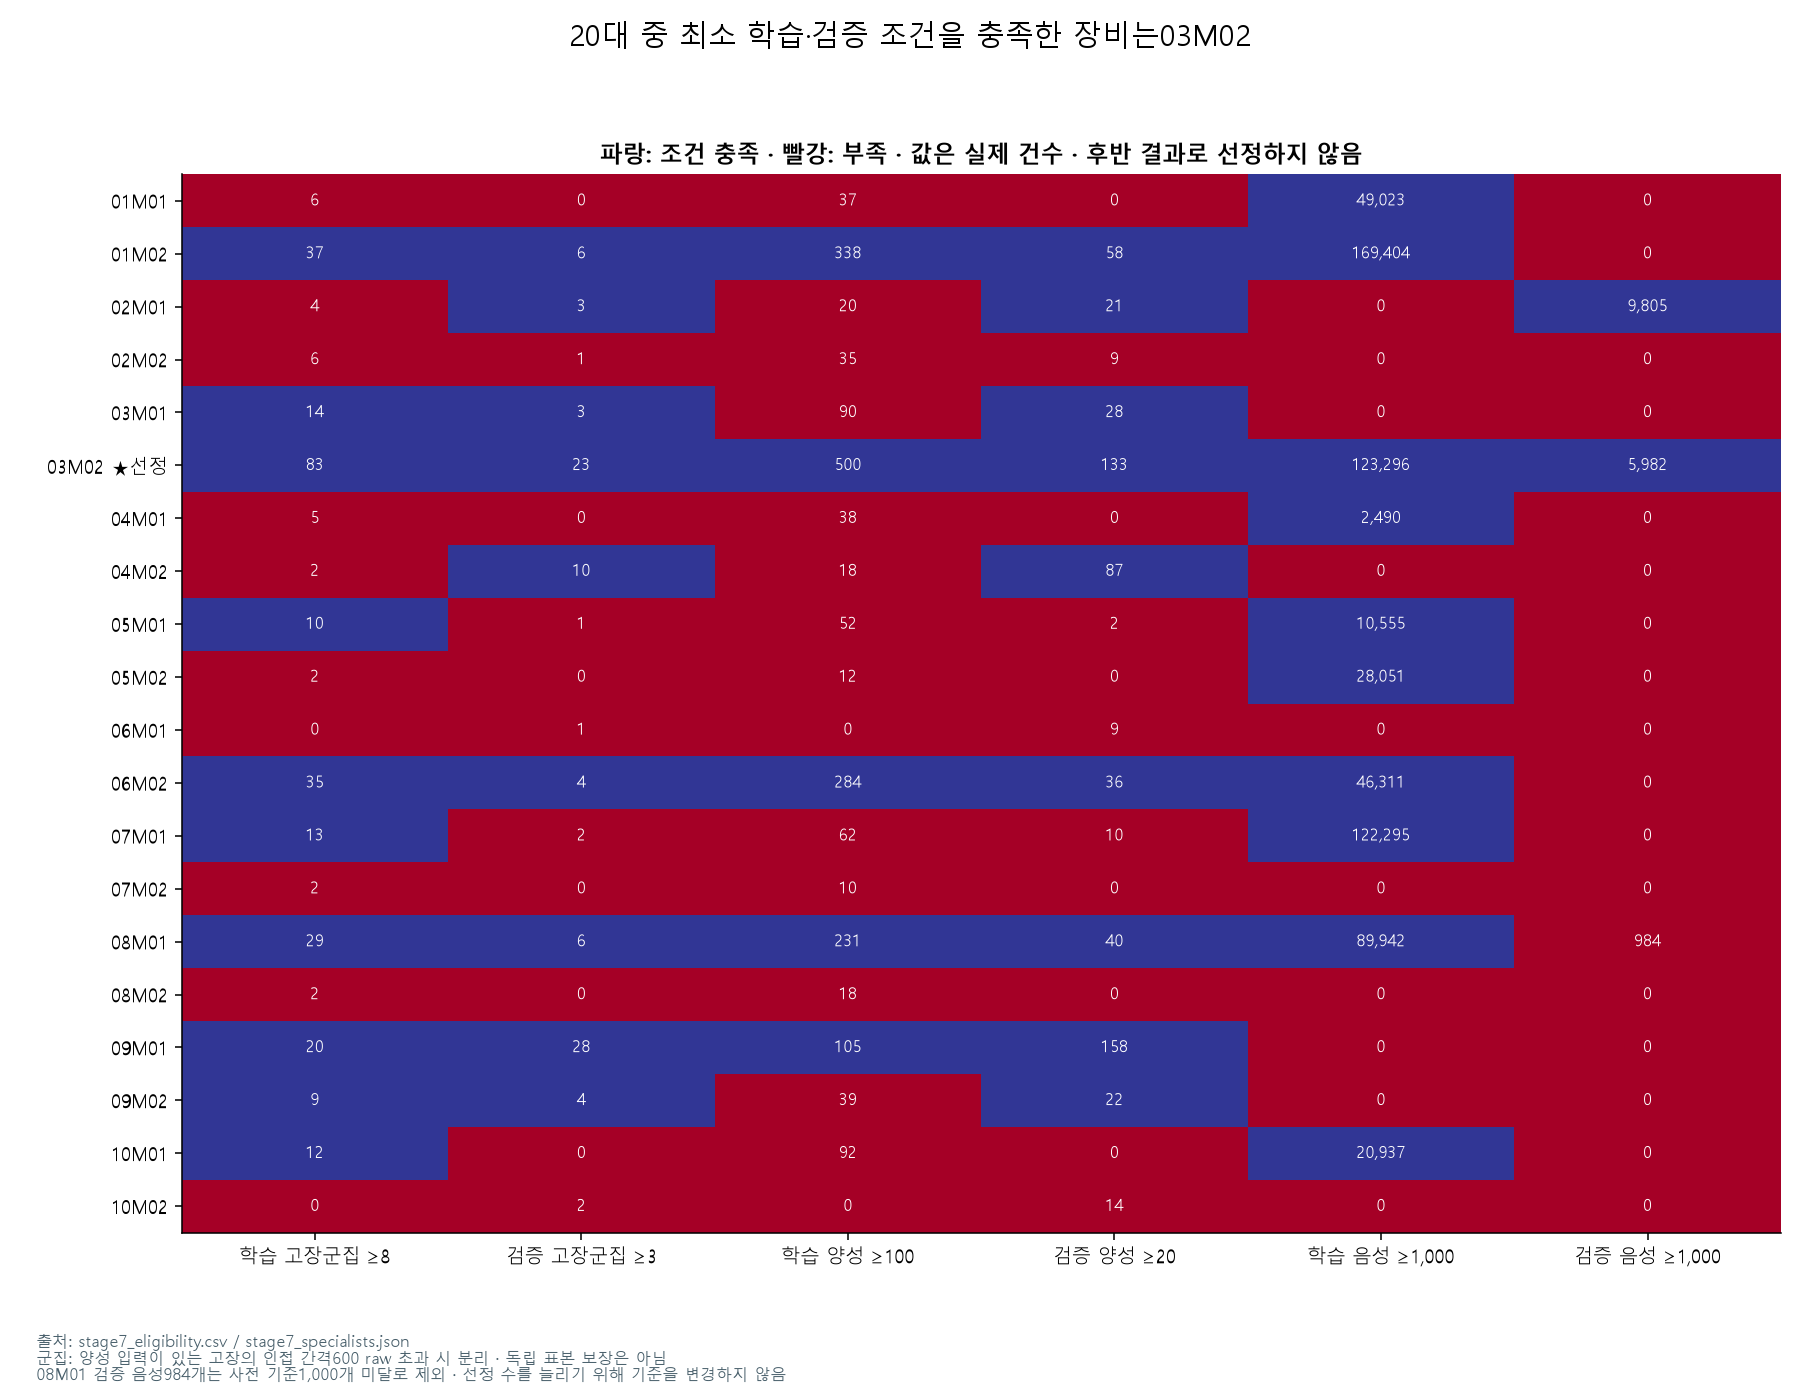

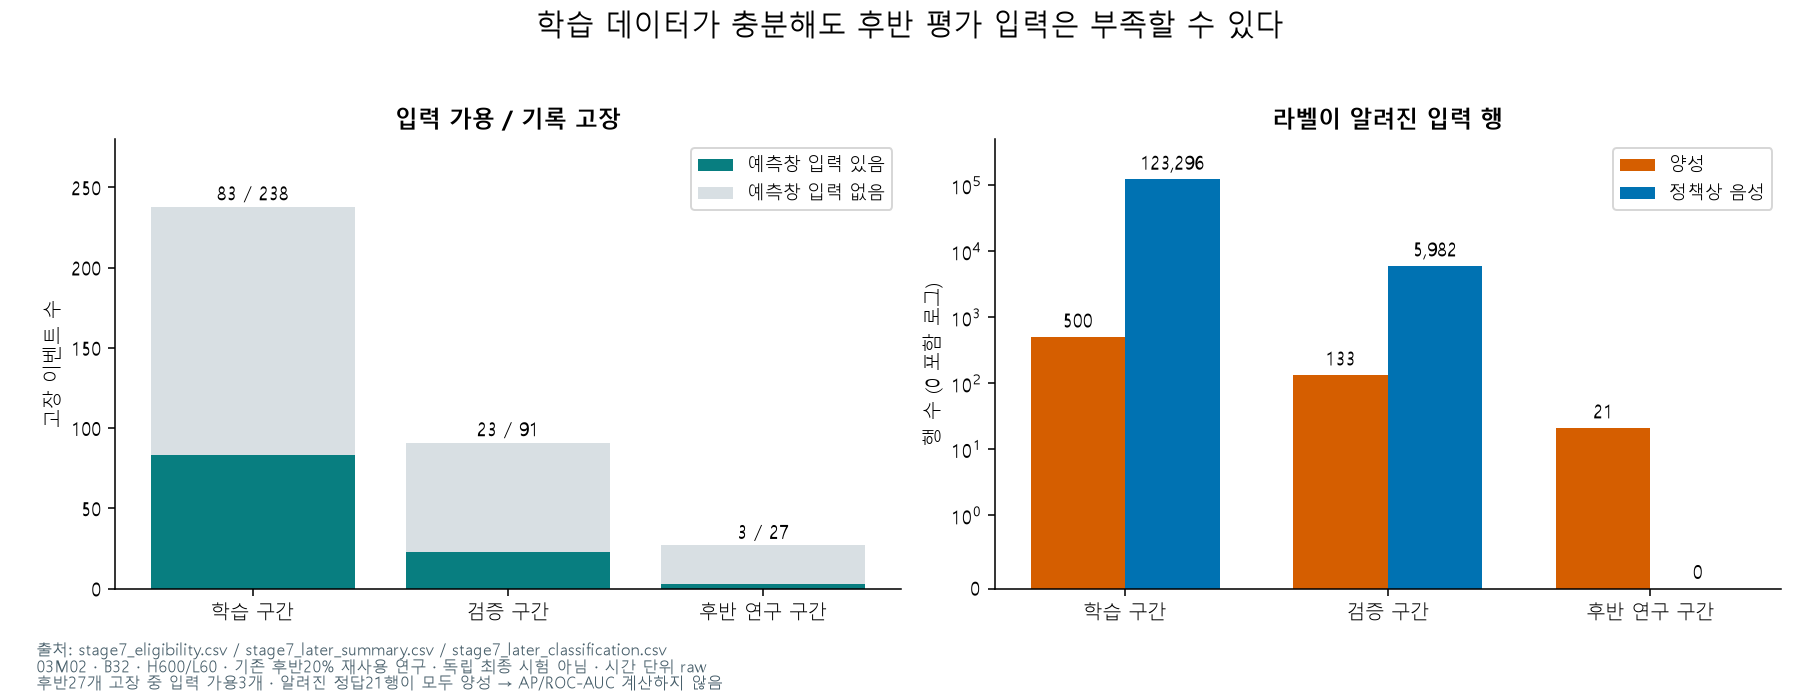

In [2]:
eligibility=table('eligibility')
expected=eligibility[list(PROTOCOL['eligibility'])].ge(pd.Series(PROTOCOL['eligibility'])).all(axis=1)
assert expected.equals(eligibility.eligible)
assert eligibility[eligibility.selected].Tool.tolist()==selection['selected_tools']
assert len(selection['selected_tools'])<=3
display(eligibility)
figure('eligibility')
figure('coverage')

## 2. CUDA 모델과 실제 입력 재현

03M02 알려진 학습123,796행(양성500/음성123,296)만 전처리와 모델 fit에 사용했습니다. B32, 깊이3, 양성 가중1, seed42로 공통 기준과 같은 설정입니다. validation 조기 종료의 선택 트리는1개입니다. 아래에서는 이미 본 validation128행을 원래 특징으로 다시 읽어 저장 모델/전처리 점수와 대조합니다. 모델이나 전처리를 다시 fit하지 않습니다.

03M02 validation 실제 입력128행 재현 일치; 후반 재추론 없음


,Tool,device,train_rows,train_positive,validation_all_rows,validation_known_rows,validation_positive,iterations,train_seconds,AP_known,ROC_AUC_known,log_loss_known
0,03M02,cuda:0,123796,500,41467,6115,133,1,0.518429,0.034911,0.548815,0.123639


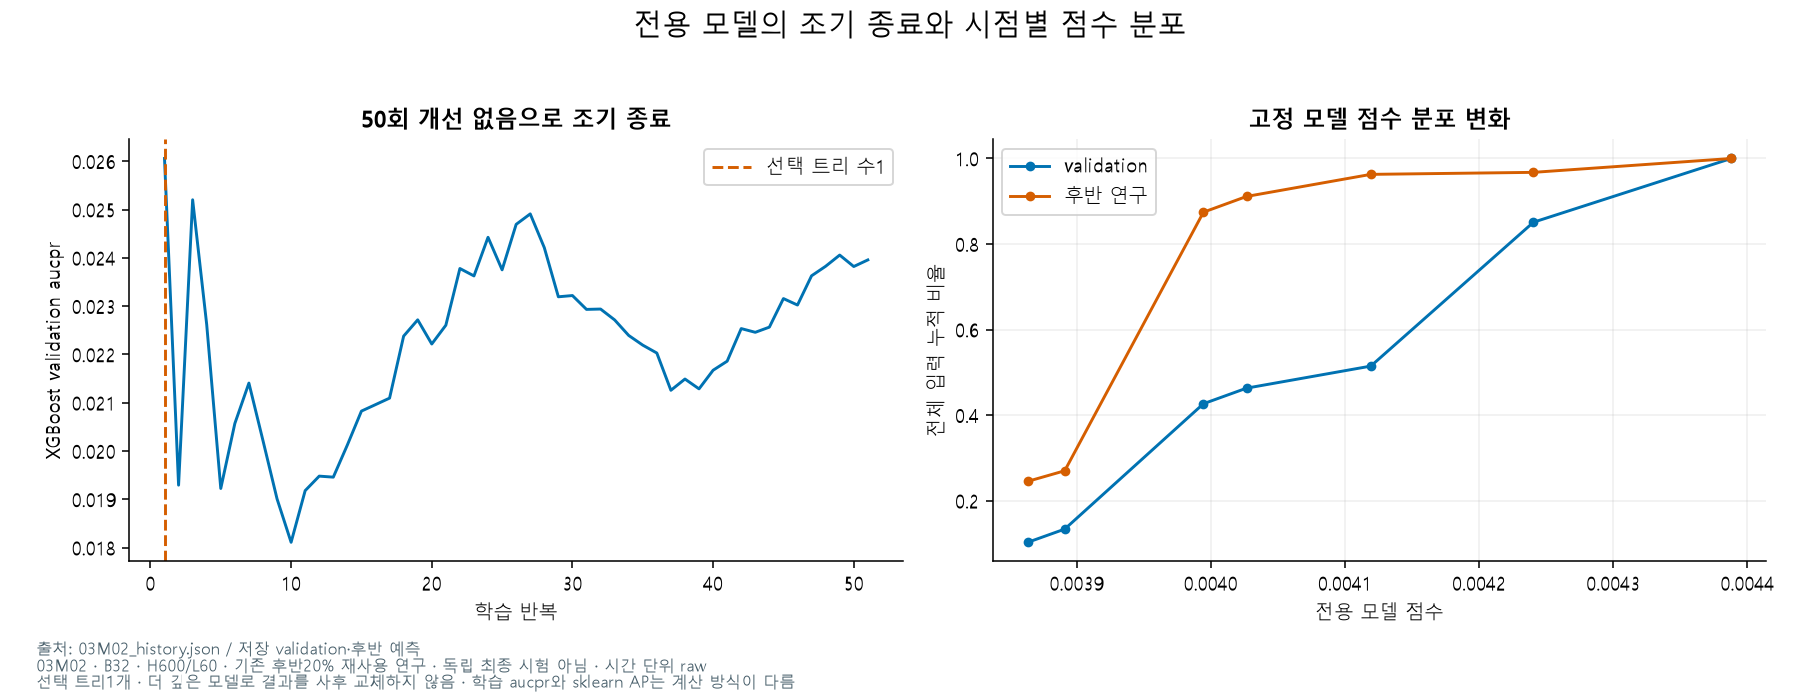

In [3]:
import joblib,xgboost as xgb
from src.features import schema
runs=table('training_summary')
assert runs.device.eq('cuda:0').all()
for tool in selection['selected_tools']:
    cfg=readjson(OUT/(tool+'_booster_config.json'))
    assert cfg['learner']['generic_param']['device']=='cuda:0'
    x,m=load('validation',tool)
    assert list(x)==schema()['B'] and not {'Tool','time','TTF','audit_label'}&set(x)
    prep=joblib.load(OUT/(tool+'_preprocessor.joblib'))
    model=joblib.load(OUT/(tool+'_model.joblib'))
    score=model.get_booster().predict(xgb.DMatrix(prep.transform(x.iloc[:128]).astype('float32')),iteration_range=(0,model.best_iteration+1))
    saved=pd.read_parquet(OUT/(tool+'_validation_predictions.parquet'))
    np.testing.assert_allclose(score,saved.score.iloc[:128],rtol=1e-6,atol=1e-7)
    print(tool,'validation 실제 입력128행 재현 일치; 후반 재추론 없음')
display(runs)
figure('learning')

## 3. 세 방식과 동결 임계값

공통·기존 임계값 / 공통·장비별 임계값 / 장비 전용을 동일 입력으로 비교합니다. 두 장비별 방식의 숫자 임계값은 validation에서만 선택하고 후반 예측 전에 동결했습니다. 기존 공통 임계값은 전체 장비 기준이므로03M02의 개별 상한을 보장하지 않습니다.

,Tool,method,budget,threshold,detected_events,available_events,recorded_events,alarm_episodes_per_10000_raw
0,03M02,specialist,5,0.004388,1,23,91,0.814926
1,03M02,specialist,10,0.004241,7,23,91,9.335387
2,03M02,global_tool_threshold,5,0.003267,2,23,91,1.676786
3,03M02,global_tool_threshold,10,0.003267,2,23,91,1.676786
4,03M02,global_frozen,5,0.003267,2,23,91,1.676786
5,03M02,global_frozen,10,0.002999,11,23,91,16.345461


,Tool,method,budget,threshold
0,03M02,specialist,5,0.004388
1,03M02,specialist,10,0.004241
2,03M02,global_tool_threshold,5,0.003267
3,03M02,global_tool_threshold,10,0.003267
4,03M02,global_frozen,5,0.003267
5,03M02,global_frozen,10,0.002999


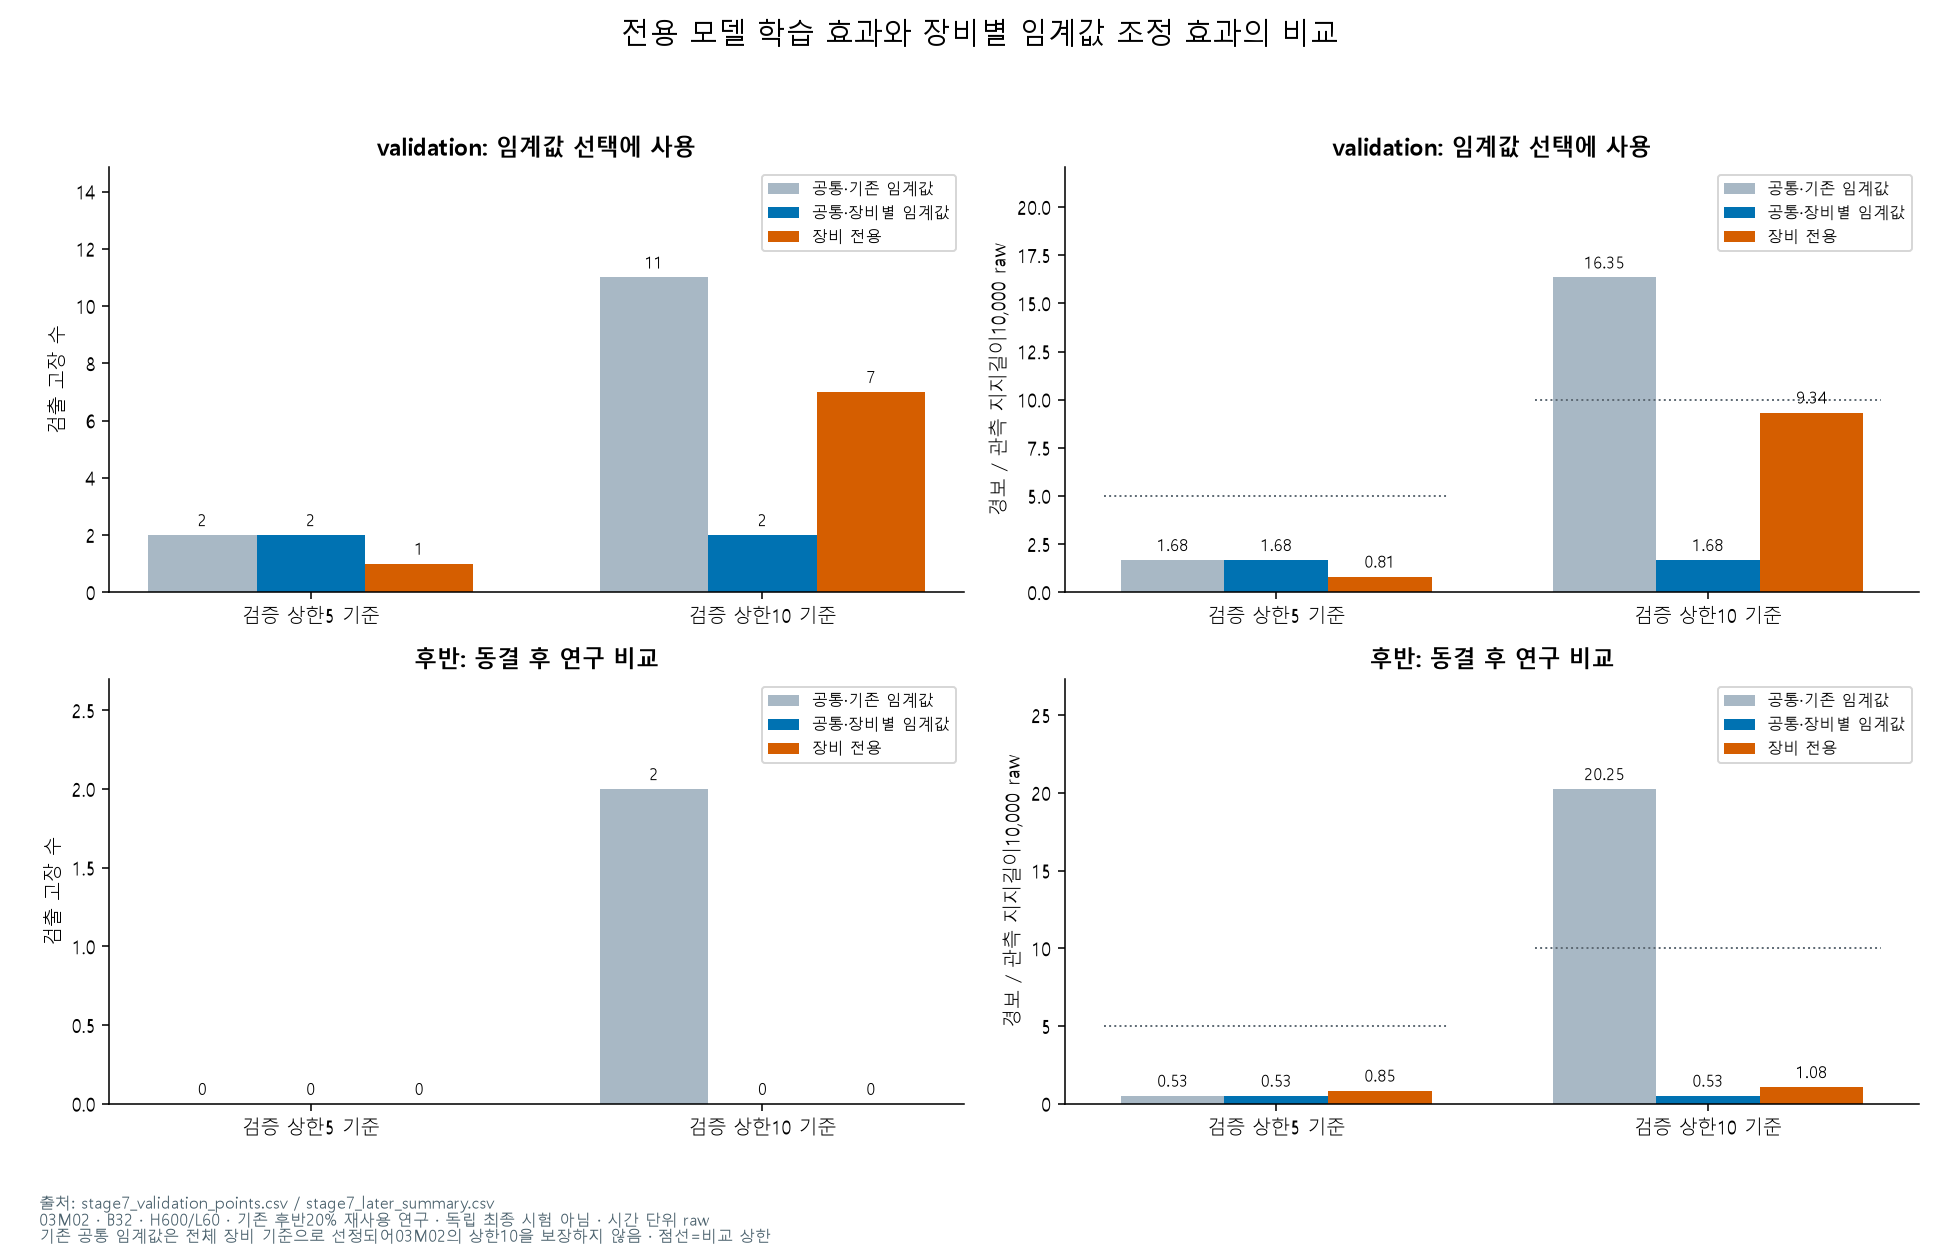

In [4]:
from datetime import datetime
assert datetime.fromisoformat(frozen['frozen_at_utc'])<datetime.fromisoformat(access['opened_at_utc'])
assert digest(OUT/'frozen_manifest.json')==access['frozen_manifest_sha256']
for path,h in frozen['sha256'].items():assert digest(ROOT/path)==h,path
points=table('validation_points')
display(points[['Tool','method','budget','threshold','detected_events','available_events','recorded_events','alarm_episodes_per_10000_raw']])
display(pd.DataFrame(frozen['points']))
figure('comparison')

## 4. 저장된 후반 예측과 경보 부담

기록27개 중 입력 가용3개입니다. 전용 모델은0개 검출/경보228·289개였고, 공통·장비별 임계값도0개 검출/141개 경보였습니다. 기존 공통 높은 설정은2개를 검출했으나 경보5,411개, 부담20.253/10,000 raw로 비교 상한10을 넘었습니다. 이를 동일 부담에서의 우월성으로 주장하지 않습니다.

후반의 알려진 라벨21행이 모두 양성이므로 AP/ROC-AUC는 미산출입니다. 대부분 경보는 미확인 시작이며 확정 오경보가 아닙니다.

,장비,방식,검증 비교상한,동결 임계값,검출,기록 고장,입력 가용 고장,전체 경보,경보/10000 raw,미확인 시작 경보
0,03M02,장비 전용,5,0.0043878452852368355,0,27,3,228,0.853399,228
1,03M02,장비 전용,10,0.0042405198328197002,0,27,3,289,1.081721,289
2,03M02,공통·장비별 임계값,5,0.0032673857640475035,0,27,3,141,0.527760,141
3,03M02,공통·장비별 임계값,10,0.0032673857640475035,0,27,3,141,0.527760,141
4,03M02,공통·기존 임계값,5,0.0032673857640475035,0,27,3,141,0.527760,141
5,03M02,공통·기존 임계값,10,0.002999492222443223,2,27,3,5411,20.253265,5409


,Tool,budget,control,recorded,available,both_detected,specialist_only,control_only,neither
0,03M02,5,global_frozen,27,3,0,0,0,27
1,03M02,5,global_tool_threshold,27,3,0,0,0,27
2,03M02,10,global_frozen,27,3,0,0,2,25
3,03M02,10,global_tool_threshold,27,3,0,0,0,27


,Tool,method,all_rows,known_rows,positive,AP_known,ROC_AUC_known
0,03M02,specialist,48164,21,21,NaN,NaN
1,03M02,global,48164,21,21,NaN,NaN


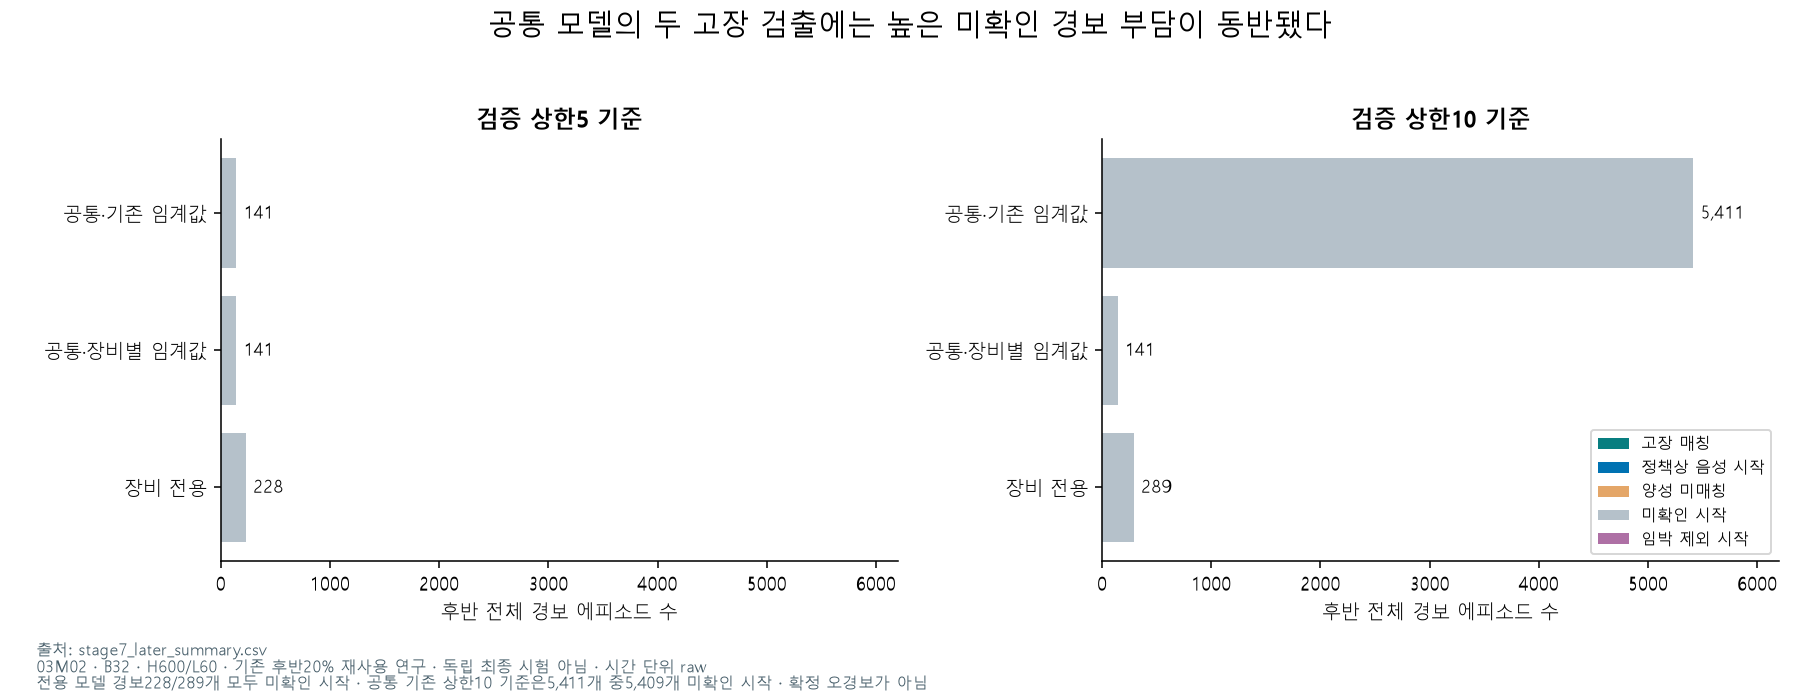

In [5]:
summary=table('later_summary')
common=pd.read_parquet(ROOT/'outputs/stage6/holdout_predictions.parquet')
for tool in selection['selected_tools']:
    p=pd.read_parquet(OUT/(tool+'_later_predictions.parquet'))
    assert digest(OUT/(tool+'_later_predictions.parquet'))==access['prediction_sha256'][tool]
    g=common[common.Tool.eq(tool)].sort_values('time').reset_index(drop=True)
    pd.testing.assert_frame_equal(p.drop(columns='score'),g.drop(columns='score'))
    for point in [r for r in frozen['points'] if r['Tool']==tool]:
        r=summary[summary.Tool.eq(tool)&summary.method.eq(point['method'])&summary.budget.eq(point['budget'])].iloc[0]
        assert r.threshold==point['threshold']
display(table('comparison_display'))
display(table('paired_events'))
display(table('later_classification'))
figure('alarm_burden')

## 5. 실제 고장 구간과 결론

공통 모델만 검출한 첫 고장과 두 모델 모두 놓친 입력 가용 고장을 사후 설명용으로 선정했습니다. 실제 센서와 저장 예측만 표시하며 공백/세그먼트를 연결하지 않습니다. 전용 모델을 만든다는 것만으로 개선되지는 않았습니다.03M02의 입력 누락24개 고장과 다른 장비의 음성 라벨 부족 원인을 먼저 확인하는 것이 다음 우선순위입니다.

이번 전용 모델은 연구 산출물로 보존하고 기존 모델을 대체하지 않습니다. 추후 개선에는 새 검증 자료가 필요합니다. 한 대/가용 고장3개로 일반화 우월성이나 통계적 유의성을 주장하지 않습니다.

,event_id,fault_time,selection
0,03M02-low-82dacf8b63d3,36618598.0,공통 모델만 검출한 첫 사례
1,03M02-high-e2143bdac86a,37568158.0,두 모델 모두 놓친 입력 가용 사례


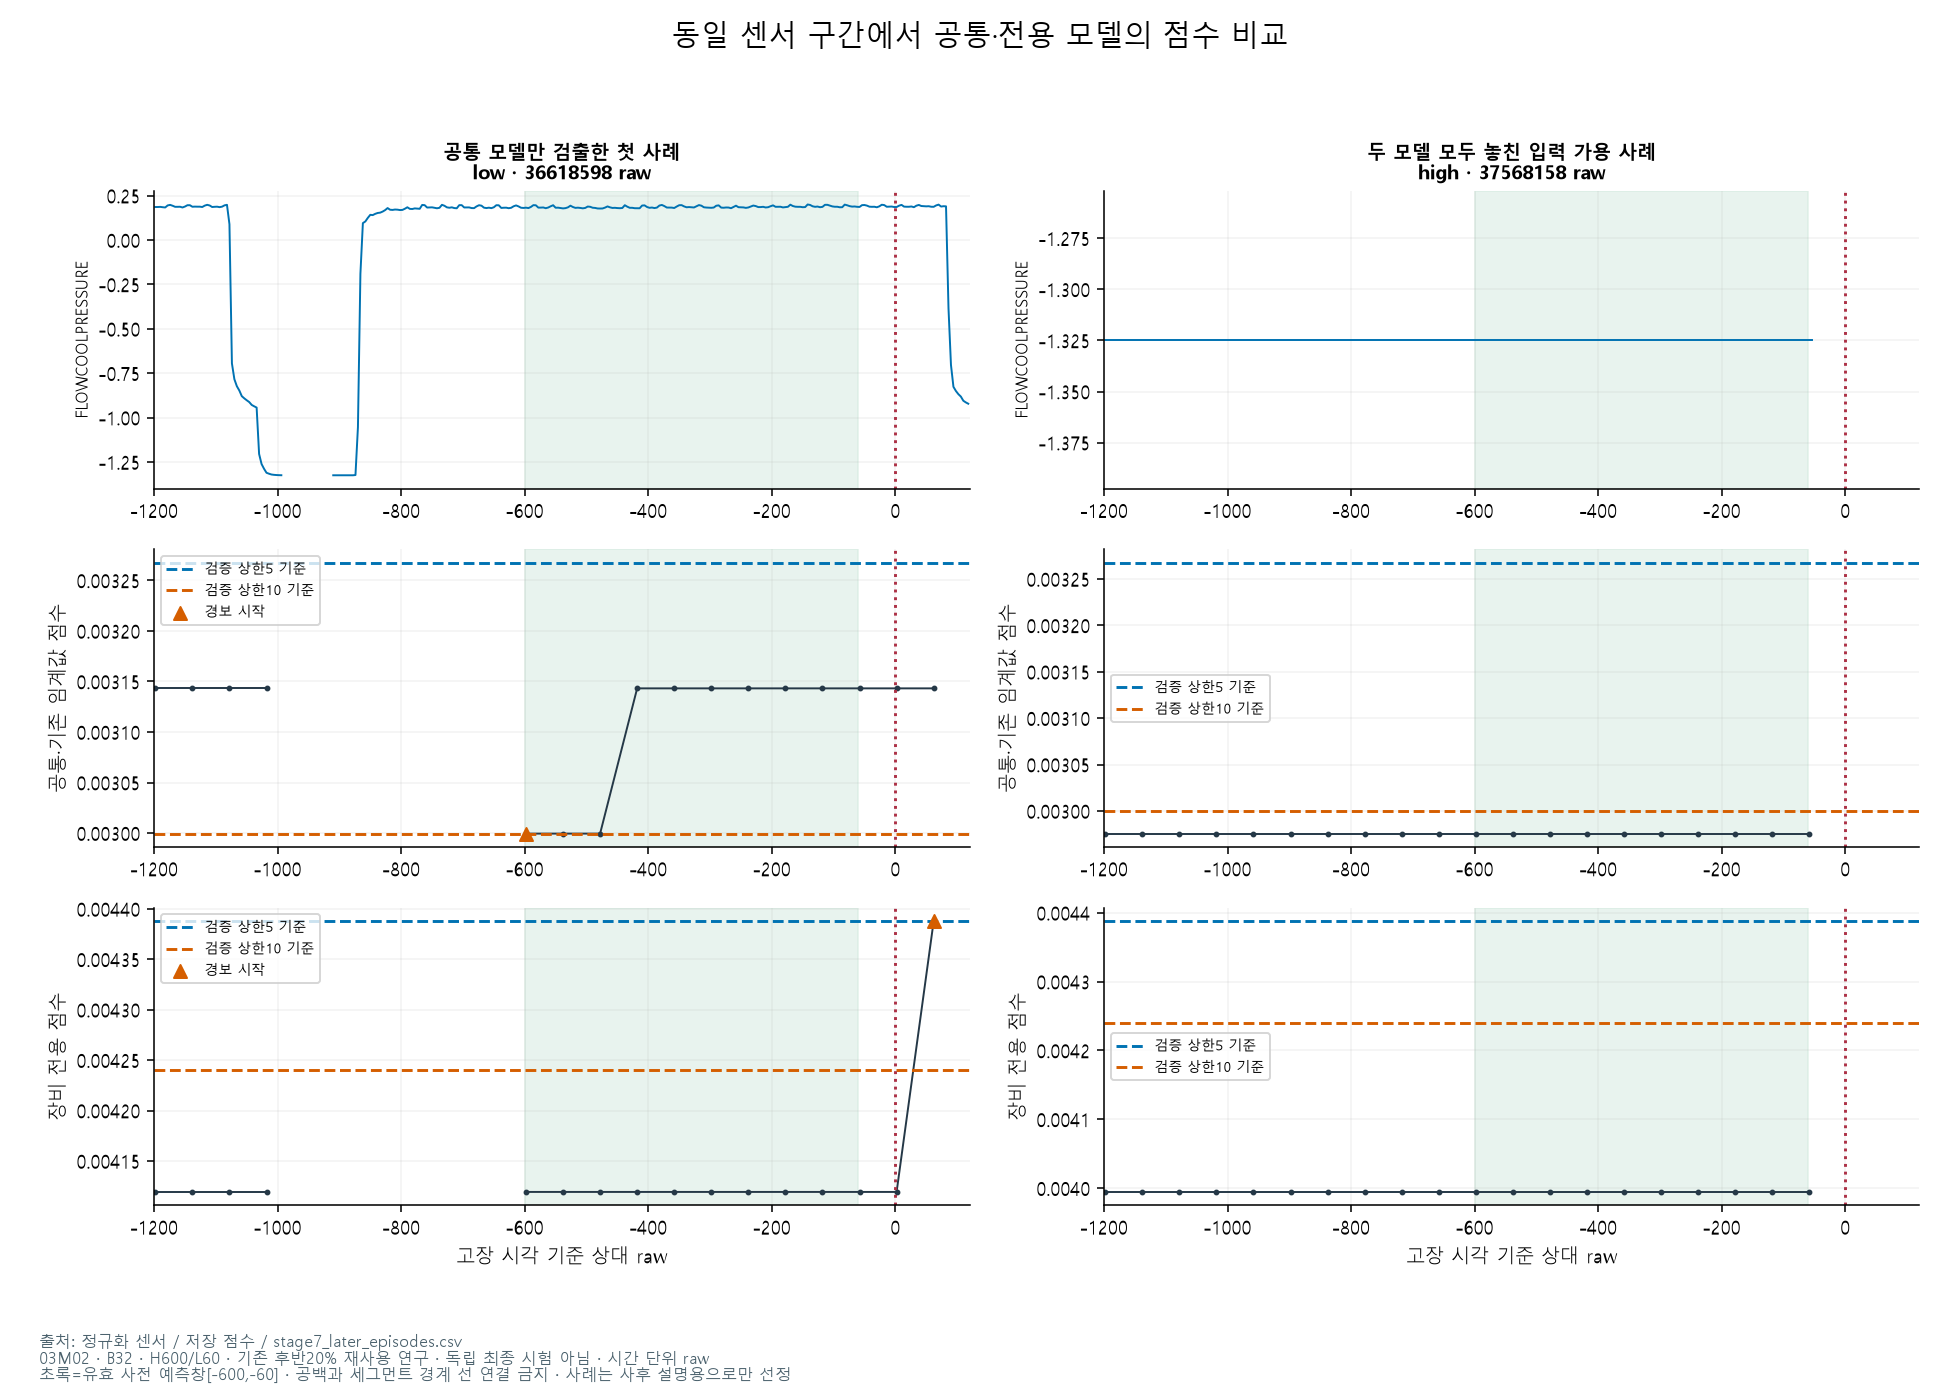

실제 산출물 검사: 130 PASS · 기존 최종 결과 보존
Notebook 후반 추론0회 · 재학습0회 · 임계값 탐색0회


In [6]:
display(pd.DataFrame([{k:v for k,v in c.items() if k!='query'} for c in readjson(OUT/'case_examples.json')]))
figure('event_cases')
checks=readjson(OUT/'checks.json')
assert all(c['passed'] for c in checks['checks'])
assert checks['additional_later_inference_during_validation']==0
verify_previous()
print('실제 산출물 검사:',len(checks['checks']),'PASS · 기존 최종 결과 보존')
print('Notebook 후반 추론0회 · 재학습0회 · 임계값 탐색0회')